# Netflix Movies and TV Shows — Data Science Capstone Project
### NumPy • Pandas • Matplotlib • Seaborn

**Project objective:** Explore a real-world Netflix titles dataset, understand its structure, clean data quality issues, discover patterns through visualizations, and prepare useful features for further analysis.

**Project workflow**
1. Load the dataset
2. Understand the data
3. Clean the data
4. Perform Exploratory Data Analysis (EDA)
5. Prepare features
6. Summarize findings and export results



## 01 - Import Libraries

- **NumPy:** numerical calculations and arrays.
- **Pandas:** loading, cleaning, and analyzing tabular data.
- **Matplotlib:** creating charts.
- **Seaborn:** making statistical visualizations easier to create and read.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use a consistent style for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


## 02 — Load the Dataset

### 2.1 Read the CSV file

**Explanation:** We load the Netflix titles CSV into a Pandas DataFrame called `df`. A DataFrame is a table-like structure containing rows and columns. The code first attempts to download the dataset; if the download fails, it asks us to upload `netflix_titles.csv` manually.

In [ ]:
# Public CSV dataset source
url = (
    "https://raw.githubusercontent.com/prasertcbs/basic-dataset/refs/heads/master/netflix_titles.csv"
)

try:
    df = pd.read_csv(url)
    print("Dataset downloaded and loaded successfully.")
except Exception as error:
    print("Automatic download failed:", error)
    print("Please upload a file named netflix_titles.csv.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv("netflix_titles.csv")

# Display the first five rows
display(df.head())

Dataset downloaded and loaded successfully.


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


## 03 — Understand the Data

### 3.1 Dataset dimensions and column names

**Explanation:** `shape` tells us the number of rows and columns. `columns` lists the variables available for analysis. This helps us understand the size and scope of the dataset.

In [ ]:
# Display number of rows and columns
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (6234, 12)
Number of rows: 6234
Number of columns: 12

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


### 3.2 Data types and structure

**Explanation:** `info()` shows each column's data type and the number of non-missing values. `dtypes` lists the data type of each column. Correct data types are important for accurate analysis.

In [ ]:
# Review data types and non-null counts
df.info()

print("\nData types by column:")
display(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       6234 non-null   int64 
 1   type          6234 non-null   object
 2   title         6234 non-null   object
 3   director      4265 non-null   object
 4   cast          5664 non-null   object
 5   country       5758 non-null   object
 6   date_added    6223 non-null   object
 7   release_year  6234 non-null   int64 
 8   rating        6224 non-null   object
 9   duration      6234 non-null   object
 10  listed_in     6234 non-null   object
 11  description   6234 non-null   object
dtypes: int64(2), object(10)
memory usage: 584.6+ KB

Data types by column:


,0
show_id,int64
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


### 3.3 Preview records and summary statistics

**Explanation:** `head()` and `tail()` show sample records. `describe()` summarizes numeric columns, while `describe(include='all')` also includes categorical columns. Statistics include count, mean, standard deviation, minimum, and maximum where applicable.

In [ ]:
# Inspect the beginning and end of the dataset
display(df.head())
display(df.tail())

# Statistical summary for numeric columns
display(df.describe())

# Summary for numeric and categorical columns
display(df.describe(include="all"))

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
6229,80000063,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaN,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil..."
6230,70286564,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaN,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews..."
6231,80116008,Movie,Little Baby Bum: Nursery Rhyme Friends,NaN,NaN,NaN,NaN,2016,NaN,60 min,Movies,Nursery rhymes and original music for children...
6232,70281022,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaN,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."
6233,70153404,TV Show,Friends,NaN,"Jennifer Aniston, Courteney Cox, Lisa Kudrow, ...",United States,NaN,2003,TV-14,10 Seasons,"Classic & Cult TV, TV Comedies",This hit sitcom follows the merry misadventure...


,show_id,release_year
count,6.234000e+03,6234.00000
mean,7.670368e+07,2013.35932
std,1.094296e+07,8.81162
min,2.477470e+05,1925.00000
25%,8.003580e+07,2013.00000
50%,8.016337e+07,2016.00000
75%,8.024489e+07,2018.00000
max,8.123573e+07,2020.00000


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,6.234000e+03,6234,6234,4265,5664,5758,6223,6234.00000,6224,6234,6234,6234
unique,NaN,2,6172,3301,5469,554,1524,NaN,14,201,461,6226
top,NaN,Movie,The Silence,"Raúl Campos, Jan Suter",David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,Documentaries,A surly septuagenarian gets another chance at ...
freq,NaN,4265,3,18,18,2032,122,NaN,2027,1321,299,3
mean,7.670368e+07,NaN,NaN,NaN,NaN,NaN,NaN,2013.35932,NaN,NaN,NaN,NaN
std,1.094296e+07,NaN,NaN,NaN,NaN,NaN,NaN,8.81162,NaN,NaN,NaN,NaN
min,2.477470e+05,NaN,NaN,NaN,NaN,NaN,NaN,1925.00000,NaN,NaN,NaN,NaN
25%,8.003580e+07,NaN,NaN,NaN,NaN,NaN,NaN,2013.00000,NaN,NaN,NaN,NaN
50%,8.016337e+07,NaN,NaN,NaN,NaN,NaN,NaN,2016.00000,NaN,NaN,NaN,NaN
75%,8.024489e+07,NaN,NaN,NaN,NaN,NaN,NaN,2018.00000,NaN,NaN,NaN,NaN


### 3.4 Unique values, missing values, and main category

**Explanation:** Unique-value counts help us understand categorical variables. Missing-value counts identify incomplete columns. The `type` column indicates whether a title is a Movie or a TV Show; we will use it as a category of interest, not as a trained prediction target.

In [ ]:
# Count unique values in every column
display(df.nunique(dropna=True).sort_values(ascending=False))

# Count missing values in every column
display(df.isnull().sum().sort_values(ascending=False))

# Review Movie versus TV Show counts
display(df["type"].value_counts(dropna=False))

,0
show_id,6234
description,6226
title,6172
cast,5469
director,3301
date_added,1524
country,554
listed_in,461
duration,201
release_year,72


,0
director,1969
cast,570
country,476
date_added,11
rating,10
title,0
show_id,0
type,0
release_year,0
duration,0


,count
type,
Movie,4265
TV Show,1969


## 04 — Clean the Data

### 4.1 Standardize column names, text, and duplicates

**Explanation:** Cleaning improves consistency. We remove exact duplicate rows, trim extra spaces in text, and treat empty strings as missing values. We preserve the original dataset in `df_raw` so the before-and-after data can be compared.

In [ ]:
# Keep a copy of the original data for comparison
df_raw = df.copy()

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Remove exact duplicate rows
print("Duplicates before cleaning:", df.duplicated().sum())
df = df.drop_duplicates().copy()

# Trim whitespace and convert empty text strings to missing values
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace("", np.nan)

print("Shape after duplicate removal:", df.shape)

Duplicates before cleaning: 0
Shape after duplicate removal: (6234, 12)


### 4.2 Convert data types and review missing values

**Explanation:** `date_added` should be a datetime column and `release_year` should be numeric. `errors='coerce'` converts values that cannot be interpreted into missing values instead of stopping the code. We inspect missing values rather than inventing replacements for fields such as director or country.

In [ ]:
# Convert columns to appropriate data types
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")

# Review missing values after type conversion
print("Missing values after cleaning:")
display(df.isnull().sum().sort_values(ascending=False))

Missing values after cleaning:


,0
director,1969
cast,570
country,476
date_added,11
rating,10
title,0
show_id,0
type,0
release_year,0
duration,0


### 4.3 Check incorrect values and potential outliers

**Explanation:** We flag release years outside a reasonable range and identify potential movie-duration outliers using the Interquartile Range (IQR) method. Outliers are flagged rather than automatically deleted because unusual values may be legitimate.

In [ ]:
# Flag release years outside a reasonable range
current_year = pd.Timestamp.now().year
invalid_year = (
    df["release_year"].notna()
    & ((df["release_year"] < 1900) | (df["release_year"] > current_year))
)
print("Invalid release-year values:", int(invalid_year.sum()))

# Replace invalid years with missing values
df.loc[invalid_year, "release_year"] = np.nan

# Extract duration number and unit, for example "90 min" or "2 Seasons"
duration_parts = df["duration"].str.extract(
    r"^\s*(\d+)\s*(min|mins|minute|minutes|season|seasons)\s*$",
    flags=0
)
df["duration_value"] = pd.to_numeric(duration_parts[0], errors="coerce")
df["duration_unit"] = duration_parts[1].str.lower()

# Standardize duration units
df["duration_unit"] = df["duration_unit"].replace({
    "mins": "min", "minute": "min", "minutes": "min",
    "seasons": "season"
})

# Find potential outliers among movie durations only
movie_minutes = df.loc[
    (df["type"] == "Movie") & (df["duration_unit"] == "min"),
    "duration_value"
].dropna()

if not movie_minutes.empty:
    q1 = movie_minutes.quantile(0.25)
    q3 = movie_minutes.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = movie_minutes[
        (movie_minutes < lower_bound) | (movie_minutes > upper_bound)
    ]
    print("Potential movie-duration outliers:", len(outliers))
    print("IQR lower and upper boundaries:", lower_bound, upper_bound)

Invalid release-year values: 0
Potential movie-duration outliers: 231
IQR lower and upper boundaries: 42.5 158.5


### 4.4 Validate the cleaned dataset

**Explanation:** We check the shape, duplicates, and remaining missing values after cleaning. Missing values can remain when the original source does not provide information; they do not always need to be filled.

In [ ]:
print("Cleaned dataset shape:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())
print("Total missing cells:", int(df.isnull().sum().sum()))

display(df.head())

Cleaned dataset shape: (6234, 14)
Remaining duplicate rows: 0
Total missing cells: 6974


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019.0,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,90.0,min
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,2016-09-09,2016.0,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,94.0,min
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013.0,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",NaN,NaN
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,2018-09-08,2016.0,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...,NaN,NaN
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,2017.0,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,99.0,min


## 05 — Exploratory Data Analysis (EDA)

**Explanation:** EDA uses summary statistics and visualizations to understand patterns, distributions, and relationships in data. Each chart below answers a different question about the Netflix catalogue.

### 5.1 Movies versus TV Shows

**Question:** How many records are Movies and how many are TV Shows?

**Interpretation guide:** Compare the bar heights. The taller bar represents the category with more titles in this dataset.

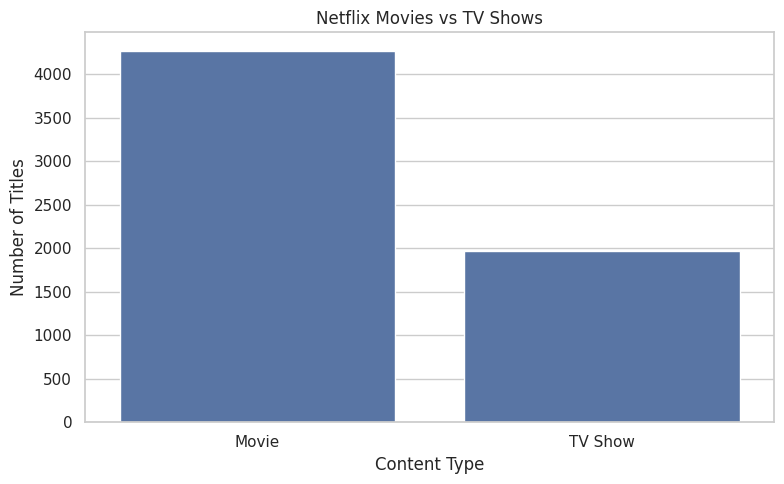

,count
type,
Movie,4265
TV Show,1969


In [ ]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=type_counts.index, y=type_counts.values)
plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

display(type_counts)

### 5.2 Titles by release year

**Question:** How are titles distributed by their original release year?

**Interpretation guide:** Peaks show years with more titles in the dataset. This chart represents release year, not the year Netflix added the title.

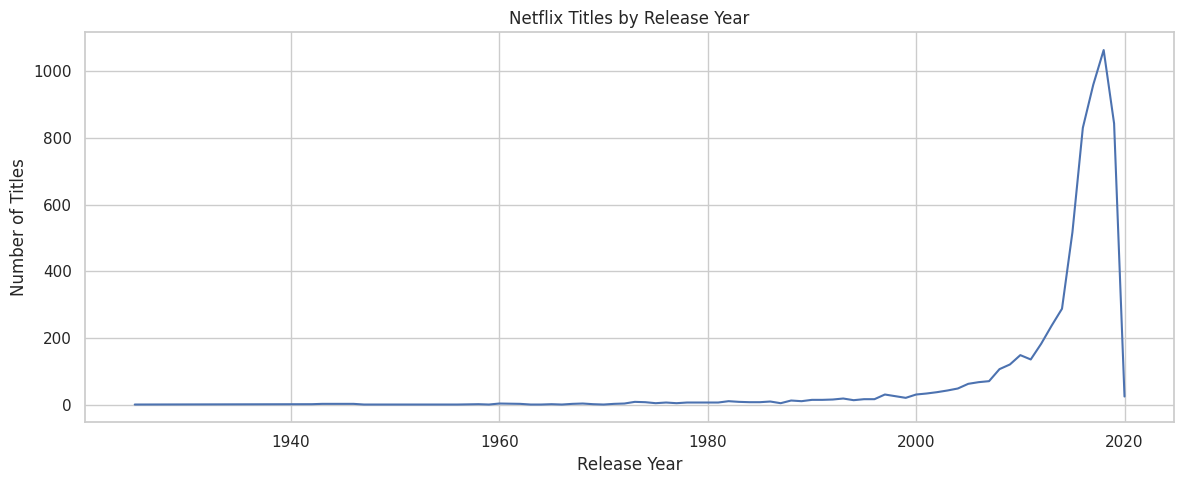

In [ ]:
year_counts = (
    df.dropna(subset=["release_year"])
      .groupby("release_year")
      .size()
      .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

### 5.3 Top countries represented

**Question:** Which countries are associated with the largest number of titles?

**Explanation:** Some titles list multiple countries. Splitting and counting each listed country means country totals can overlap; they should not be added together as if each title belonged to only one country.

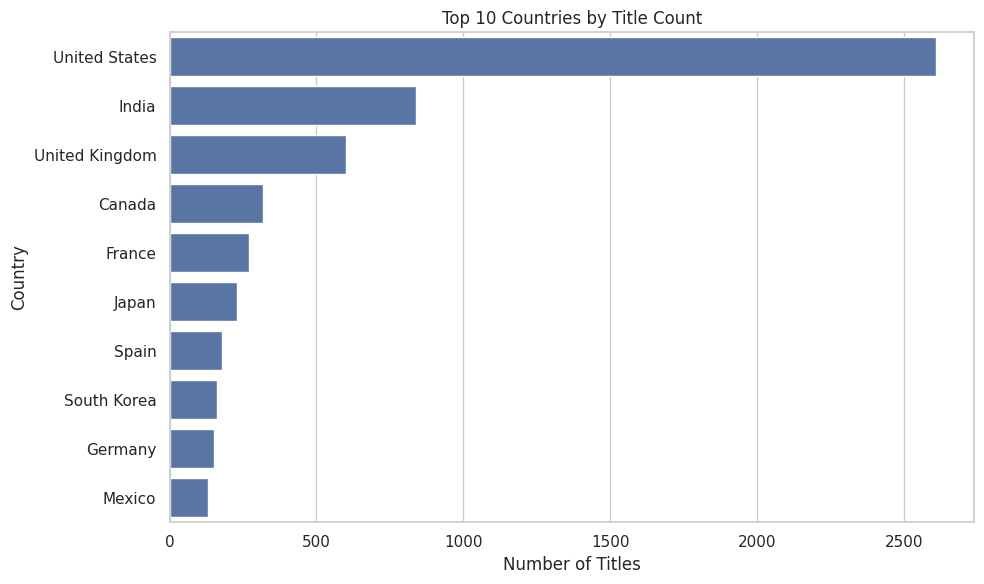

,count
country,
United States,2609
India,838
United Kingdom,601
Canada,318
France,271
Japan,231
Spain,178
South Korea,162
Germany,151


In [ ]:
country_counts = (
    df["country"].dropna()
      .str.split(", ")
      .explode()
      .value_counts()
      .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("Top 10 Countries by Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(country_counts)

### 5.4 Most common genres

**Question:** Which listed genres or categories occur most often?

**Explanation:** The `listed_in` column can contain multiple categories per title. We split these values so that each category can be counted separately.

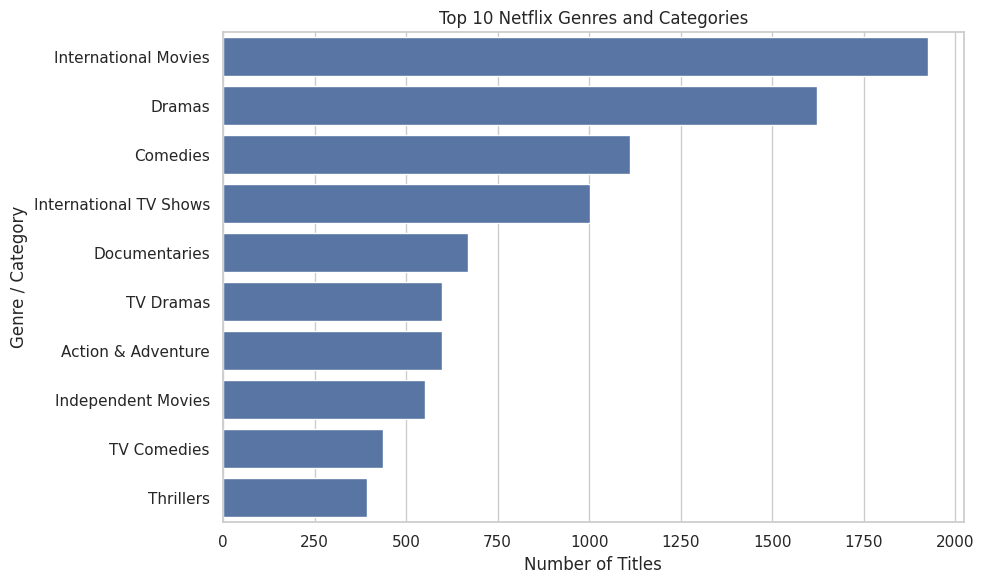

,count
listed_in,
International Movies,1927
Dramas,1623
Comedies,1113
International TV Shows,1001
Documentaries,668
TV Dramas,599
Action & Adventure,597
Independent Movies,552
TV Comedies,436


In [ ]:
genre_counts = (
    df["listed_in"].dropna()
      .str.split(", ")
      .explode()
      .value_counts()
      .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("Top 10 Netflix Genres and Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Genre / Category")
plt.tight_layout()
plt.show()

display(genre_counts)

### 5.5 Movie duration distribution

**Question:** What is the distribution of movie durations in minutes?

**Explanation:** This analysis includes Movie records measured in minutes and excludes TV Show records measured in seasons. A histogram shows the frequency of durations across ranges.

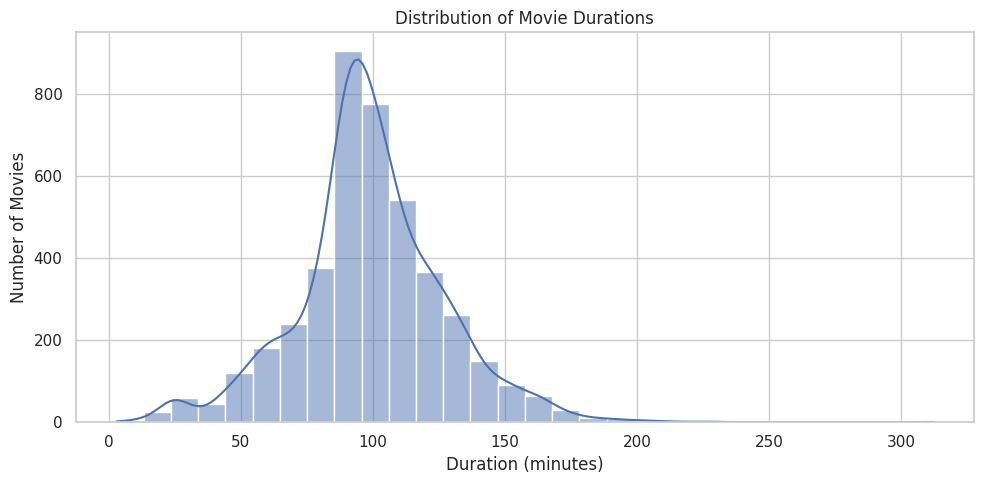

Mean duration: 99.1 minutes
Median duration: 98.0 minutes


In [ ]:
movie_df = df[
    (df["type"] == "Movie") & (df["duration_unit"] == "min")
].copy()

plt.figure(figsize=(10, 5))
sns.histplot(data=movie_df, x="duration_value", bins=30, kde=True)
plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

print("Mean duration:", round(movie_df["duration_value"].mean(), 2), "minutes")
print("Median duration:", round(movie_df["duration_value"].median(), 2), "minutes")

### 5.6 Titles added to Netflix over time

**Question:** How many titles were added to Netflix in each year, and how does this differ by content type?

**Explanation:** `date_added` records when a title was added to Netflix. This differs from `release_year`, which records the original release year.

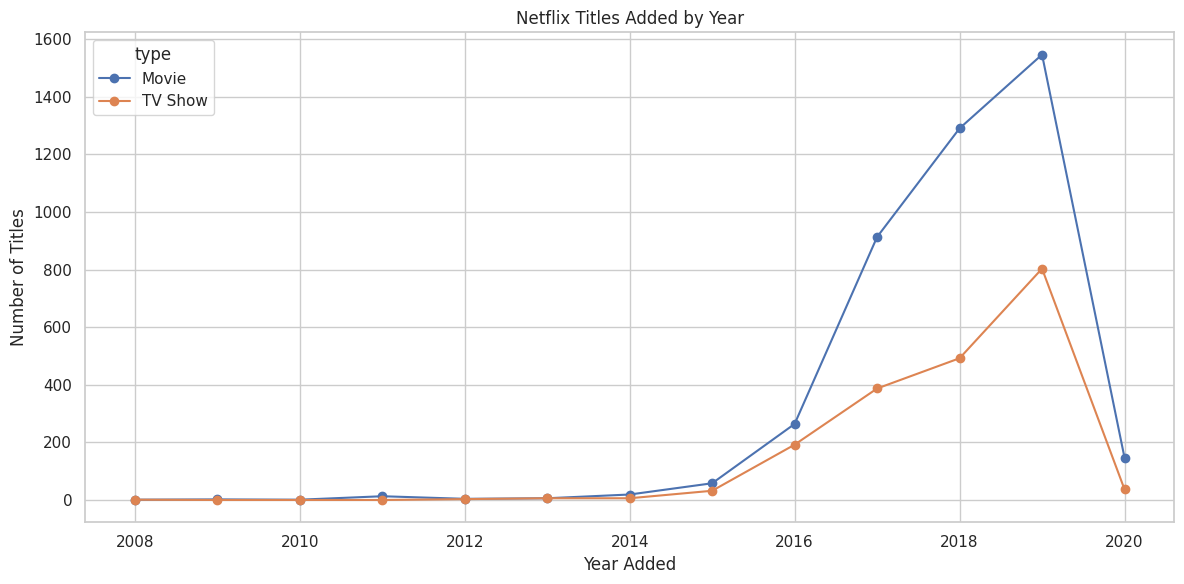

In [ ]:
dated_df = df.dropna(subset=["date_added"]).copy()
dated_df["year_added"] = dated_df["date_added"].dt.year

added_by_year = (
    dated_df.groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
)

added_by_year.plot(kind="line", marker="o", figsize=(12, 6))
plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

### 5.7 Correlation heatmap

**Question:** Are any numeric columns linearly associated?

**Explanation:** Correlation ranges from -1 to +1. Values near +1 indicate positive linear association, values near -1 indicate negative linear association, and values near 0 indicate little linear association. Correlation does not prove causation. If only a few numeric columns exist, the heatmap may contain limited information.

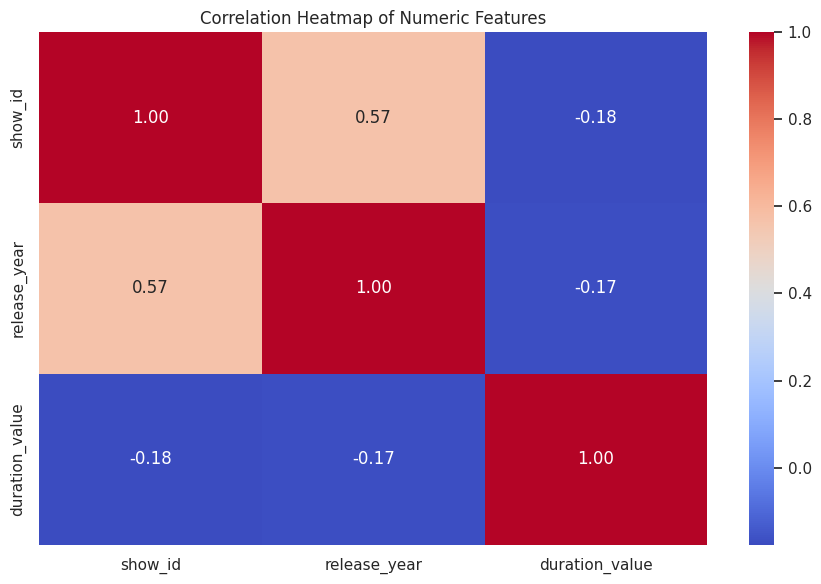

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

## 06 — Prepare Features

### 6.1 Feature engineering

**Explanation:** Feature engineering creates useful columns from existing information. Here, we extract the year and month a title was added and count the listed genres and cast members. These features can support future analysis.

In [ ]:
features_df = df.copy()

# Extract year and month from the date a title was added
features_df["added_year"] = features_df["date_added"].dt.year
features_df["added_month"] = features_df["date_added"].dt.month

# Count listed genres and cast members
features_df["genre_count"] = (
    features_df["listed_in"].fillna("")
    .apply(lambda x: len([item for item in x.split(", ") if item]))
)
features_df["cast_count"] = (
    features_df["cast"].fillna("")
    .apply(lambda x: len([item for item in x.split(", ") if item]))
)

# Log transformation can reduce the influence of very large positive values
features_df["log_duration"] = np.log1p(
    features_df["duration_value"].clip(lower=0)
)

display(features_df[[
    "title", "type", "added_year", "added_month",
    "genre_count", "cast_count", "duration_value", "log_duration"
]].head())

,title,type,added_year,added_month,genre_count,cast_count,duration_value,log_duration
0,Norm of the North: King Sized Adventure,Movie,2019.0,9.0,2,10,90.0,4.510860
1,Jandino: Whatever it Takes,Movie,2016.0,9.0,1,1,94.0,4.553877
2,Transformers Prime,TV Show,2018.0,9.0,1,12,NaN,NaN
3,Transformers: Robots in Disguise,TV Show,2018.0,9.0,1,8,NaN,NaN
4,#realityhigh,Movie,2017.0,9.0,1,12,99.0,4.605170


### 6.2 Encode categorical features

**Explanation:** Many algorithms require numeric inputs rather than text categories. We create indicator columns for the ten most common genres. The encoded columns are features for potential future analysis; no model is trained here.

In [ ]:
# Select the ten most frequent listed genres
top_genres = (
    features_df["listed_in"].dropna()
    .str.split(", ").explode()
    .value_counts().head(10).index
)

# Create one binary column per selected genre
for genre in top_genres:
    safe_name = "genre_" + (
        genre.lower().replace(" ", "_").replace("-", "_")
    )
    features_df[safe_name] = (
        features_df["listed_in"].fillna("")
        .apply(lambda value: int(genre in value.split(", ")))
    )

# Encode content type for a possible future classification exercise
features_df["type_encoded"] = features_df["type"].map({
    "Movie": 0,
    "TV Show": 1
})

display(features_df.head())

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,...,genre_dramas,genre_comedies,genre_international_tv_shows,genre_documentaries,genre_tv_dramas,genre_action_&_adventure,genre_independent_movies,genre_tv_comedies,genre_thrillers,type_encoded
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019.0,TV-PG,90 min,...,0,1,0,0,0,0,0,0,0,0
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,2016-09-09,2016.0,TV-MA,94 min,...,0,0,0,0,0,0,0,0,0,0
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013.0,TV-Y7-FV,1 Season,...,0,0,0,0,0,0,0,0,0,1
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,2018-09-08,2016.0,TV-Y7,1 Season,...,0,0,0,0,0,0,0,0,0,1
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,2017.0,TV-14,99 min,...,0,1,0,0,0,0,0,0,0,0


### 6.3 Scale numerical features

**Explanation:** Min-max scaling transforms values to a 0–1 range. We keep the original columns and add separate scaled columns. In a future machine-learning project, scaling parameters should be learned from training data only to prevent data leakage.

In [ ]:
scale_cols = ["release_year", "duration_value", "genre_count", "cast_count"]

for col in scale_cols:
    values = pd.to_numeric(features_df[col], errors="coerce")
    median_value = values.median()

    # Use zero only if a column has no valid values at all
    if pd.isna(median_value):
        median_value = 0

    values = values.fillna(median_value)
    min_value = values.min()
    max_value = values.max()

    if max_value > min_value:
        features_df[col + "_scaled"] = (
            (values - min_value) / (max_value - min_value)
        )
    else:
        features_df[col + "_scaled"] = 0.0

display(features_df[[c for c in features_df.columns if c.endswith("_scaled")]].head())

,release_year_scaled,duration_value_scaled,genre_count_scaled,cast_count_scaled
0,0.989474,0.281553,0.5,0.20
1,0.957895,0.294498,0.0,0.02
2,0.926316,0.307443,0.0,0.24
3,0.957895,0.307443,0.0,0.16
4,0.968421,0.310680,0.0,0.24


### 6.4 Create the final feature matrix

**Explanation:** `X` is a table containing prepared numeric features. `y` is an optional encoded content-type label for a future classification exercise. Because this notebook focuses on EDA.

In [ ]:
genre_columns = [c for c in features_df.columns if c.startswith("genre_")]
scaled_columns = [c for c in features_df.columns if c.endswith("_scaled")]

feature_columns = (
    scaled_columns
    + ["added_year", "added_month", "log_duration"]
    + genre_columns
)

X = features_df[feature_columns].copy()
y = features_df["type_encoded"].copy()

# Replace infinite values and fill remaining feature gaps
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

print("Feature matrix shape:", X.shape)
print("Optional target shape:", y.shape)
display(X.head())

Feature matrix shape: (6234, 19)
Optional target shape: (6234,)


,release_year_scaled,duration_value_scaled,genre_count_scaled,cast_count_scaled,added_year,added_month,log_duration,genre_count,genre_international_movies,genre_dramas,genre_comedies,genre_international_tv_shows,genre_documentaries,genre_tv_dramas,genre_action_&_adventure,genre_independent_movies,genre_tv_comedies,genre_thrillers,genre_count_scaled
0,0.989474,0.281553,0.5,0.20,2019.0,9.0,4.510860,2,0,0,1,0,0,0,0,0,0,0,0.5
1,0.957895,0.294498,0.0,0.02,2016.0,9.0,4.553877,1,0,0,0,0,0,0,0,0,0,0,0.0
2,0.926316,0.307443,0.0,0.24,2018.0,9.0,0.000000,1,0,0,0,0,0,0,0,0,0,0,0.0
3,0.957895,0.307443,0.0,0.16,2018.0,9.0,0.000000,1,0,0,0,0,0,0,0,0,0,0,0.0
4,0.968421,0.310680,0.0,0.24,2017.0,9.0,4.605170,1,0,0,1,0,0,0,0,0,0,0,0.0


## 07 — Key Findings and Conclusion

**Explanation:** This section summarizes key statistics calculated from the dataset. After running the notebook, use the outputs and charts above to write conclusions in your own words. Avoid claiming that one factor causes another unless the analysis supports that conclusion.

In [ ]:
# Calculate concise summary statistics
print("FINAL PROJECT SUMMARY")
print("-" * 40)
print("Total titles:", len(df))
print("Movies:", int((df["type"] == "Movie").sum()))
print("TV Shows:", int((df["type"] == "TV Show").sum()))
print("Titles with a missing country:", int(df["country"].isna().sum()))
print("Titles with a missing director:", int(df["director"].isna().sum()))

if not movie_df.empty:
    print("Median movie duration (minutes):",
          round(movie_df["duration_value"].median(), 2))

print("\nSuggested conclusion prompts:")
print("1. Which content type appears more frequently?")
print("2. Which genres and countries appear most often?")
print("3. What patterns are visible in release years and additions?")
print("4. What limitations did missing or multi-valued fields create?")

FINAL PROJECT SUMMARY
----------------------------------------
Total titles: 6234
Movies: 4265
TV Shows: 1969
Titles with a missing country: 476
Titles with a missing director: 1969
Median movie duration (minutes): 98.0

Suggested conclusion prompts:
1. Which content type appears more frequently?
2. Which genres and countries appear most often?
3. What patterns are visible in release years and additions?
4. What limitations did missing or multi-valued fields create?


## 08 — Export Processed Data

**Explanation:** Exporting makes the cleaned dataset and engineered features reusable outside this notebook. CSV files can be opened in spreadsheet software or imported into another Python project.

In [ ]:
# Export cleaned data and prepared features
df.to_csv("netflix_cleaned.csv", index=False)
features_df.to_csv("netflix_features_engineered.csv", index=False)
X.to_csv("netflix_feature_matrix.csv", index=False)
y.to_csv("netflix_target.csv", index=False)

print("Export completed:")
print("- netflix_cleaned.csv")
print("- netflix_features_engineered.csv")
print("- netflix_feature_matrix.csv")
print("- netflix_target.csv")

Export completed:
- netflix_cleaned.csv
- netflix_features_engineered.csv
- netflix_feature_matrix.csv
- netflix_target.csv


### Download a result from Google Colab

Run the following code in a separate cell to download the engineered dataset to your computer.

In [ ]:
from google.colab import files
files.download("netflix_features_engineered.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project Complete

Completed a reproducible data science workflow covering:
- Data loading and inspection
- Data cleaning and validation
- Exploratory data analysis and visualizations
- Feature engineering, categorical encoding, and scaling
- Exporting processed data

**Next step:** Review each visualization, write 2–3 evidence-based observations, and be prepared to explain why each cleaning or feature-preparation step was performed.